# 21 キャンペーン予定と実際のクーポン利用

過去の全注文明細に、同日・同店舗・同商品カテゴリの割引キャンペーン予定を結び付け、実際にクーポンが付いた割合を調べる。2025年については事前の予定だけを集計する。

**注意**: 日・店舗・カテゴリの一致は粗い代理条件であり、各顧客・時刻・商品がクーポンの利用資格を満たすことを保証しない。適用有無は顧客の選択や他のルールに依存するため、これは利用可能な人の利用率でも施策の因果効果でもない。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir():ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.set_option('display.max_columns',40);pd.options.display.float_format='{:,.4f}'.format
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']];store_ids=stores.store_id.tolist()
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','category','menu_type']]
campaign=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
campaign['store_id']=campaign.store_ids.map(lambda x:store_ids if x=='all' else x.split('|'))
campaign=campaign.explode('store_id',ignore_index=True)
assert not campaign.duplicated(['date','store_id','campaign_id']).any()
coupons=campaign[campaign.coupon_flag].copy().rename(columns={'target_item_group':'category'})
assert coupons.category.isin(menus.category.unique()).all()
plans=coupons.groupby(['date','store_id','category'],observed=True).agg(planned_count=('campaign_id','nunique'),max_planned_rate=('discount_rate','max')).reset_index()
assert not plans.duplicated(['date','store_id','category']).any()
print('展開後の割引施策予定:',len(coupons),'日×店舗×カテゴリ:',len(plans))

展開後の割引施策予定: 4488 日×店舗×カテゴリ: 4345


## 全注文明細と粗い予定条件の照合
同日・店舗・カテゴリの予定件数を明細に付ける。予定が複数ある場合、上限率を記録するが、同時適用や割引率の合算は仮定しない。

In [2]:
parts=[];quality=[];applied_type=[]
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in store_ids:
        with z.open(f'logs/{sid}/order_items.parquet') as f:
            o=pq.read_table(io.BytesIO(f.read()),columns=['date','item_id','quantity','list_price_amount','discount_amount','net_sales_amount','applied_coupon_campaign_id']).to_pandas()
        o=o.merge(menus[['item_id','category']],on='item_id',validate='many_to_one')
        p=plans[plans.store_id.eq(sid)].drop(columns='store_id')
        o=o.merge(p,on=['date','category'],how='left',validate='many_to_one')
        o['planned_count']=o.planned_count.fillna(0).astype(int);o['applied']=o.applied_coupon_campaign_id.notna();o['year']=o.date.dt.year;o['weekday']=o.date.dt.dayofweek
        o['applied_without_proxy_plan']=o.applied & o.planned_count.eq(0)
        q={'store_id':sid,'lines':len(o),'applied':int(o.applied.sum()),'applied_without_proxy_plan':int(o.applied_without_proxy_plan.sum()),'lines_with_multiple_plans':int(o.planned_count.gt(1).sum())};quality.append(q)
        parts.append(o.groupby(['year','category','weekday','planned_count'],observed=True).agg(lines=('item_id','size'),applied=('applied','sum'),quantity=('quantity','sum'),gross=('list_price_amount','sum'),discount=('discount_amount','sum'),net=('net_sales_amount','sum')).reset_index().assign(store_id=sid))
        applied_type.append(o[o.applied].groupby(['category','planned_count','applied_coupon_campaign_id'],observed=True).size().rename('lines').reset_index().assign(store_id=sid))
        print(sid,'lines:',len(o),'applied:',q['applied'],flush=True)
        del o
quality=pd.DataFrame(quality);history=pd.concat(parts,ignore_index=True);applied_type=pd.concat(applied_type,ignore_index=True)
display(quality)
print('全明細:',int(quality.lines.sum()),'クーポン付:',int(quality.applied.sum()),'粗い予定条件に一致しないクーポン付明細:',int(quality.applied_without_proxy_plan.sum()))
assert quality.lines.sum()==8417590 and quality.applied.sum()==186619

S001 lines: 1006670 applied: 12964
S002 lines: 866515 applied: 14221
S003 lines: 964313 applied: 32344
S004 lines: 1112487 applied: 39972
S005 lines: 801335 applied: 22536
S006 lines: 596023 applied: 10056
S007 lines: 731885 applied: 10336
S008 lines: 684457 applied: 16617
S009 lines: 579569 applied: 13816
S010 lines: 1074336 applied: 13757
全明細: 8417590 クーポン付: 186619 粗い予定条件に一致しないクーポン付明細: 0


,store_id,lines,applied,applied_without_proxy_plan,lines_with_multiple_plans
0,S001,1006670,12964,0,1538
1,S002,866515,14221,0,402
2,S003,964313,32344,0,1236
3,S004,1112487,39972,0,2136
4,S005,801335,22536,0,628
5,S006,596023,10056,0,666
6,S007,731885,10336,0,528
7,S008,684457,16617,0,500
8,S009,579569,13816,0,345
9,S010,1074336,13757,0,892


## カテゴリ・予定数別の過去の実績
「付与率」の分母は該当する粗い条件の全注文明細。実際にクーポン利用資格を持っていた顧客だけを分母とする率ではない。

複数予定を含む場合でも、実際に記録された適用IDの件数を集計。予定率の合計は用いていない。


,category,planned_count,lines,applied,quantity,gross,discount,net,applied_fraction,discount_over_gross
0,dessert,0,493414,0,493717,252543650,0,252543650,0.0000,0.0000
1,dessert,1,137752,91880,137844,70477440,3015701,67461739,0.6670,0.0428
2,dessert,2,8871,7755,8880,4527140,267546,4259594,0.8742,0.0591
3,drink_bar,0,1850556,0,3268461,829976390,0,829976390,0.0000,0.0000
4,kids,0,305605,0,315024,200850720,0,200850720,0.0000,0.0000
5,kids,1,22690,15035,23479,14980830,498985,14481845,0.6626,0.0333
6,lunch,0,726565,0,745465,591748730,0,591748730,0.0000,0.0000
7,lunch,1,38424,17613,39383,31150210,1145506,30004704,0.4584,0.0368
8,main,0,3593192,0,3743743,3644025730,0,3644025730,0.0000,0.0000
9,main,1,146793,54336,154063,150821020,5692453,145128567,0.3702,0.0377


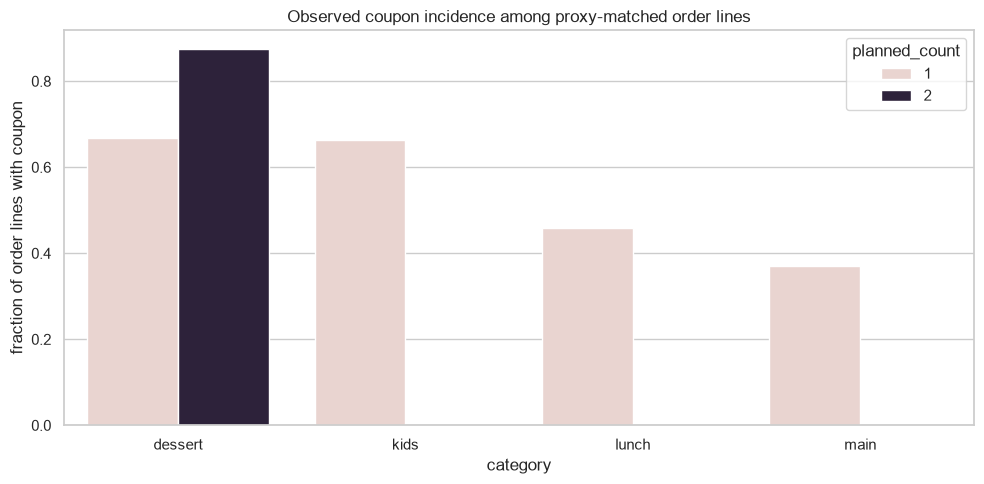

,category,planned_count,applied_coupon_campaign_id,lines
1,dessert,1,RULE_RAINY_DESSERT,55068
0,dessert,1,RULE_DESSERT_FAIR,36812
2,dessert,2,RULE_DESSERT_FAIR,5759
3,dessert,2,RULE_RAINY_DESSERT,1996
4,kids,1,RULE_KIDS_SMILE,15035
5,lunch,1,RULE_WEEKDAY_LUNCH,17613
6,main,1,RULE_FAMILY_WEEKEND,54336


In [3]:
hist=history.groupby(['category','planned_count'],observed=True)[['lines','applied','quantity','gross','discount','net']].sum().reset_index()
hist['applied_fraction']=hist.applied/hist.lines;hist['discount_over_gross']=hist.discount/hist.gross
display(hist)
fig,ax=plt.subplots(figsize=(10,5));sns.barplot(data=hist[hist.planned_count.gt(0)],x='category',y='applied_fraction',hue='planned_count',ax=ax);ax.set(title='Observed coupon incidence among proxy-matched order lines',ylabel='fraction of order lines with coupon');plt.tight_layout();plt.show()
types=applied_type.groupby(['category','planned_count','applied_coupon_campaign_id'],observed=True).lines.sum().reset_index()
display(types.sort_values(['category','planned_count','lines'],ascending=[True,True,False]))
print('複数予定を含む場合でも、実際に記録された適用IDの件数を集計。予定率の合計は用いていない。')

## 曜日と店舗によるばらつき
条件一致した明細のクーポン付与割合。曜日・店舗ごとに客層、商品、キャンペーンの種類、時間が異なる。

,store_id,category,weekday,lines,applied,fraction
64,S004,main,6,22922,9583,0.4181
45,S003,main,6,21467,8204,0.3822
63,S004,main,5,20467,8336,0.4073
44,S003,main,5,18085,6795,0.3757
82,S005,main,6,16354,5393,0.3298
81,S005,main,5,14495,4633,0.3196
137,S009,main,5,10150,3399,0.3349
138,S009,main,6,6994,2251,0.3218
119,S008,lunch,2,5337,2572,0.4819
121,S008,lunch,4,5262,2573,0.4890


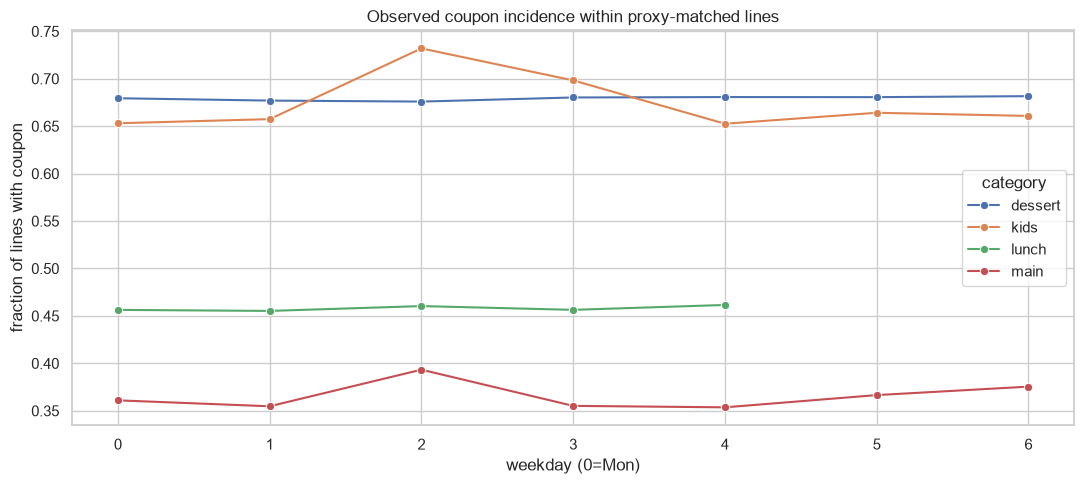

In [4]:
group=history[history.planned_count.gt(0)].groupby(['store_id','category','weekday'],observed=True)[['lines','applied']].sum().reset_index();group['fraction']=group.applied/group.lines
display(group.sort_values('lines',ascending=False).head(30))
weekly=group.groupby(['category','weekday'],observed=True)[['lines','applied']].sum().reset_index();weekly['fraction']=weekly.applied/weekly.lines
fig,ax=plt.subplots(figsize=(11,5));sns.lineplot(data=weekly,x='weekday',y='fraction',hue='category',marker='o',ax=ax);ax.set(title='Observed coupon incidence within proxy-matched lines',xlabel='weekday (0=Mon)',ylabel='fraction of lines with coupon');plt.tight_layout();plt.show()

## 2025年の予定と対象予測枠
カタログ期間とコラボ参加店舗に基づいて販売可能と判定した日×店舗×商品行に、同じ日・店舗・カテゴリの予定を付ける。これは**予測枠数**であり、将来の注文件数やクーポン利用数ではない。

In [5]:
test=pd.read_csv(INPUT/'test.csv',parse_dates=['date']).drop(columns='sales_amount')
catalog=pd.read_csv(INPUT/'menu_catalog_history.csv',parse_dates=['effective_start_date','effective_end_date'])
catalog['date']=[pd.date_range(a,b) for a,b in zip(catalog.effective_start_date,catalog.effective_end_date)]
catalog=catalog.explode('date',ignore_index=True)[['date','item_id','campaign_id']].assign(catalog_active=True)
assert not catalog.duplicated(['date','item_id']).any()
participants=campaign[['date','store_id','campaign_id']].assign(campaign_active=True)
test=(test.merge(menus,on='item_id',validate='many_to_one')
      .merge(catalog,on=['date','item_id'],how='left',validate='many_to_one')
      .merge(participants,on=['date','store_id','campaign_id'],how='left',validate='many_to_one')
      .merge(plans,on=['date','store_id','category'],how='left',validate='many_to_one'))
test['eligible']=test.catalog_active.fillna(False).astype(bool)&(test.menu_type.ne('collaboration')|test.campaign_active.fillna(False).astype(bool))
test['planned_count']=test.planned_count.fillna(0).astype(int);test['month']=test.date.dt.month
future=test[test.eligible].groupby(['category','planned_count'],observed=True).size().rename('eligible_item_days').reset_index()
display(future)
monthly=test[test.eligible].groupby(['month','category'],observed=True).agg(eligible_item_days=('item_id','size'),item_days_with_plan=('planned_count',lambda x:x.gt(0).sum()),item_days_with_multiple_plans=('planned_count',lambda x:x.gt(1).sum())).reset_index()
display(monthly)
assert len(test)==306600 and test.eligible.sum()==230028
print('販売可能と判定された予測枠:',int(test.eligible.sum()),'／',len(test),'。将来の利用数や売上を表さない。')

販売可能と判定された予測枠: 230028 ／ 306600 。将来の利用数や売上を表さない。


,category,planned_count,eligible_item_days
0,dessert,0,39070
1,dessert,1,8832
2,dessert,2,484
3,drink_bar,0,7300
4,kids,0,21196
5,kids,1,1028
6,lunch,0,42408
7,lunch,1,1392
8,main,0,60940
9,main,1,2046


,month,category,eligible_item_days,item_days_with_plan,item_days_with_multiple_plans
0,1,dessert,4300,347,0
1,1,drink_bar,620,0,0
2,1,kids,1860,78,0
3,1,lunch,3720,156,0
4,1,main,5540,178,0
...,...,...,...,...,...
67,12,drink_bar,620,0,0
68,12,kids,1860,96,0
69,12,lunch,3720,192,0
70,12,main,5270,102,0


## 解釈
- 過去のクーポン適用実績は2025年の同日には未観測。利用割合を特徴量にするなら基準日以前から集計し、時間順に検証する。
- 対象商品群の記載は利用可能性を完全に定義しない。時間・客層・券の取得・複数施策などが影響する可能性がある。
- 粗い予定条件に一致する明細の割合は、施策の介入効果でも、顧客ベースの利用率でもない。